In [4]:
!pip install scikit-learn pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\USER\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


# STAGE 2 — MACHINE LEARNING (UNSUPERVISED & SUPERVISED)

#### 📊 Import Thư Viện Học Máy & Đọc Dữ Liệu Stage 2

* **Import thư viện**: Tải các thư viện chuyên dụng cho học không giám sát và tiền xử lý (`KMeans` phân cụm, `PCA` giảm chiều dữ liệu, `StandardScaler` chuẩn hóa dữ liệu).
* **Đọc dữ liệu**: Tải file `Master_Stage1.csv` từ giai đoạn trước vào DataFrame (`df`), sau đó in ra kích thước và hiển thị các dòng đầu tiên để chuẩn bị bước vào phân tích Machine Learning.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns     
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Đọc file dữ liệu sạch từ Stage 1
df = pd.read_csv('Master_Stage1.csv')
print("Kích thước dữ liệu đầu vào Stage 2:", df.shape)
display(df.head())

Kích thước dữ liệu đầu vào Stage 2: (100101, 12)


,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level,Depression,Extracurricular_Hours
0,1001.0,22,Female,Science,3.50,7.3,3.3,3.4,114.0,5.0,0,7
1,1002.0,20,Male,Engineering,2.72,5.5,7.2,6.0,142.0,2.0,0,4
2,1003.0,20,Male,Medical,3.01,5.4,2.3,1.8,137.0,3.0,0,4
3,1004.0,21,Male,Engineering,3.63,8.1,2.0,4.6,130.0,3.0,0,13
4,1005.0,19,Male,Arts,3.14,6.8,2.6,4.3,4.0,6.0,0,11


## TASK 1: UNSUPERVISED LEARNING & PCA

#### 📈 Phân Tích Không Giám Sát & Giảm Chiều Dữ Liệu (PCA)

* **Chọn lọc đặc trưng**: Lọc ra các biến số chuyên sâu phục vụ phân tích (CGPA, thời gian ngủ, thời gian học, mạng xã hội, hoạt động thể chất, mức độ căng thẳng, giờ ngoại khóa) và loại bỏ các dòng thiếu dữ liệu (`dropna`).
* **Chuẩn hóa dữ liệu (`StandardScaler`)**: Đưa các đặc trưng về cùng một thang đo (có trung bình bằng 0 và độ lệch chuẩn bằng 1) để đảm bảo các biến có trọng số công bằng trong thuật toán.
* **Tính toán phương sai tích lũy (`PCA`)**: Áp dụng phân tích thành phần chính để tính tỷ lệ phương sai giải thích được của từng thành phần, từ đó xác định số chiều tối thiểu cần giữ lại để đạt ngưỡng thông tin mong muốn ($\ge 85\%$).
* **Trực quan hóa**: Vẽ biểu đồ đường thể hiện mức độ tích lũy phương sai theo số lượng thành phần chính kèm đường chuẩn ngưỡng 85%, giúp người xem dễ dàng đánh giá và lựa chọn số chiều phù hợp.

Số chiều cần thiết để giữ lại >= 85% phương sai: 6


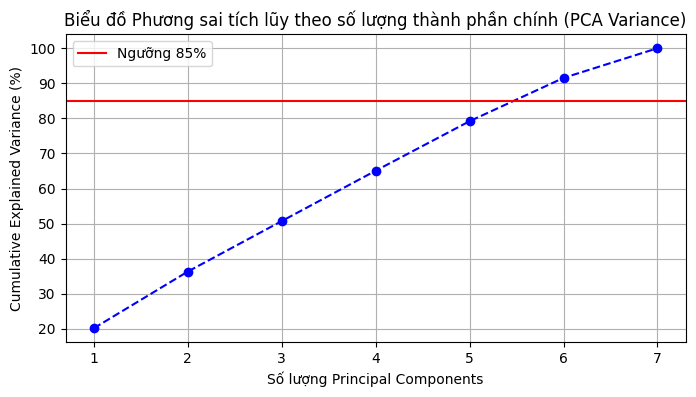

In [ ]:
# ==========================================
# TASK 1: UNSUPERVISED LEARNING & PCA (VÕ HÀ MINH THẮNG)
# ==========================================
features = [
    "CGPA",
    "Sleep_Duration",
    "Study_Hours",
    "Social_Media_Hours",
    "Physical_Activity",
    "Stress_Level",
    "Extracurricular_Hours",
]

# Lọc các cột số cần thiết và drop giá trị thiếu
df_task1 = df[features].dropna().copy()

# 1. Chuẩn hóa dữ liệu
X_scaled = StandardScaler().fit_transform(df_task1)

# 2. Tính toán phương sai tích lũy
X_pca_full = PCA().fit(X_scaled)
cum_variance = np.cumsum(X_pca_full.explained_variance_ratio_)

# Tìm số chiều tối thiểu để giữ lại từ 85% đến 95% phương sai
n_components = np.argmax(cum_variance >= 0.85) + 1
print(f"Số chiều cần thiết để giữ lại >= 85% phương sai: {n_components}")

# Biểu đồ phương sai tích lũy
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_variance) + 1), cum_variance * 100, marker="o", linestyle="--", color="b")
plt.axhline(y=85, color="r", linestyle="-", label="Ngưỡng 85%")
plt.xlabel("Số lượng Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Biểu đồ Phương sai tích lũy theo số lượng thành phần chính (PCA Variance)")
plt.legend()
plt.grid(True)
plt.show()


##### Phân tích Biểu đồ PCA Variance
* **Trục hoành**: Số lượng thành phần chính (từ 1 đến 7)[cite: 2].
* **Trục tung**: Tỷ lệ phương sai tích lũy (%)[cite: 2].
* **Đường đỏ (85%)**: Ngưỡng chuẩn lượng thông tin cần giữ lại[cite: 2].
* **Đường xanh**: 
  * 5 thành phần đạt ~79% (chưa đủ)[cite: 2].
  * **6 thành phần** đạt ~91.5% (vượt ngưỡng 85%)[cite: 2].
  * 7 thành phần đạt 100% (giữ nguyên gốc)[cite: 2].

👉 **Kết luận**: Chọn **6 thành phần chính** để giảm chiều dữ liệu mà vẫn giữ lại hơn **90%** thông tin quan trọng[cite: 2].

-----

### 📉 Giảm Chiều Dữ Liệu Xuống 2D bằng PCA

* **Khởi tạo (`n_components=2`)**: Cấu hình thuật toán PCA để nén dữ liệu từ không gian nhiều chiều xuống còn 2 chiều.
* **Chuyển đổi (`fit_transform`)**: Áp dụng lên dữ liệu đã chuẩn hóa (`X_scaled`) để tạo ra không gian 2D (`X_pca`), chuẩn bị cho việc vẽ biểu đồ phân cụm trực quan.

In [13]:
# 3. Chạy PCA giảm xuống 2 chiều để vẽ biểu đồ phân cụm 2D trực quan
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

-----

## TASK 2: K-MEANS CLUSTERING & PHÂN CỤM SINH VIÊN

#### 🎯 Đánh Giá Số Lượng Cụm Tối Ưu (K-Means)

* **Thư viện đánh giá**: Import hàm `silhouette_score` từ `sklearn.metrics`.
* **Khởi tạo thông số**: Thiết lập danh sách kiểm tra số cụm `K_range` từ 2 đến 5 (`range(2, 6)`), khai báo các mảng lưu trữ độ đo `inertias` (Inertia) và `silhouette_scores` (Silhouette Score).
* **Lấy mẫu dữ liệu tối ưu**: Trích xuất ngẫu nhiên tối đa 3.000 mẫu (`X_pca_sample`) từ không gian 2D để tăng tốc độ tính toán hệ số Silhouette.
* **Vòng lặp huấn luyện**: Chạy thuật toán `KMeans` với từng giá trị $k$, tính toán độ biến thiên trong cụm (`inertia_`) trên toàn bộ dữ liệu và đo lường độ tách biệt các cụm (`silhouette_score`) trên tập mẫu.

In [ ]:
# ==========================================
# TASK 2: K-MEANS CLUSTERING & PHÂN CỤM SINH VIÊN (VÕ HÀ MINH THẮNG)
# ==========================================
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
K_range = range(2, 6)

# Lấy mẫu ngẫu nhiên để tính silhouette nhanh hơn
sample_idx = np.random.choice(X_pca.shape[0], size=min(3000, X_pca.shape[0]), replace=False)
X_pca_sample = X_pca[sample_idx]

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertias.append(km.inertia_)
    labels_sample = km.predict(X_pca_sample)
    silhouette_scores.append(silhouette_score(X_pca_sample, labels_sample))

### Biểu đồ Elbow Method

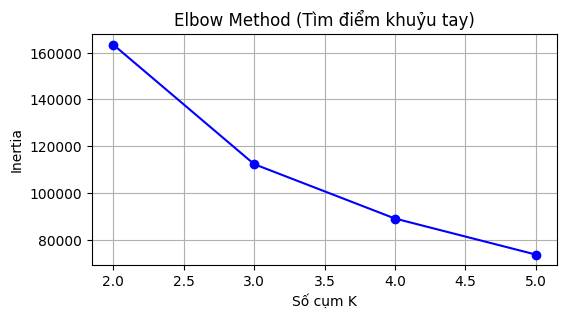

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(K_range, inertias, "b-o")
plt.title("Elbow Method (Tìm điểm khuỷu tay)")
plt.xlabel("Số cụm K")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

##### 📊 Phân tích Biểu đồ Elbow Method

* **Trục hoành**: Số lượng cụm $K$ (từ 2 đến 5)[cite: 2].
* **Trục tung**: Giá trị Inertia (độ biến thiên trong cụm)[cite: 2].
* **Diễn biến đường cong**: 
  * Giá trị Inertia giảm đều khi tăng số lượng cụm[cite: 2].
  * Đường đi khá thoải, **không xuất hiện điểm "khuỷu tay" (elbow)** rõ rệt hay điểm gãy khúc tường minh[cite: 2].

👉 **Kết luận**: Phương pháp Elbow chưa đưa ra một mốc $K$ tối ưu rõ ràng, do đó cần xem xét thêm biểu đồ **Silhouette Score** để quyết định số lượng cụm chính xác[cite: 2].

---

### Biểu đồ Silhouette Score

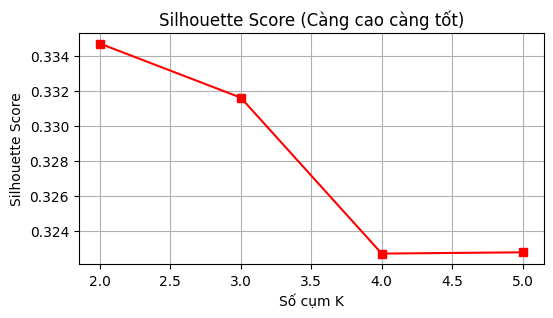

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(K_range, silhouette_scores, "r-s")
plt.title("Silhouette Score (Càng cao càng tốt)")
plt.xlabel("Số cụm K")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

##### 📊 Phân tích Biểu đồ Silhouette Score

* **Trục hoành**: Số lượng cụm $K$ (từ 2 đến 5)[cite: 3].
* **Trục tung**: Giá trị Silhouette Score (độ tách biệt giữa các cụm, giá trị càng cao càng tốt)[cite: 3].
* **Diễn biến đường cong**: 
  * Điểm số đạt mức **cao nhất tại $K = 2$** (khoảng $\approx 0.335$)[cite: 3].
  * Sau đó, giá trị giảm dần rõ rệt khi tăng số lượng cụm lên $K = 3$, $4$ và chạm đáy thấp nhất ở khoảng $K = 4, 5$ ($\approx 0.323$)[cite: 3].

👉 **Kết luận**: Dựa trên độ đo Silhouette, số lượng cụm tối ưu nhất là **$K = 2$**, giúp các cụm dữ liệu phân tách rõ ràng và có chất lượng gom nhóm tốt nhất[cite: 3].

-------

#### 🏷️ Phân Cụm K-Means ($K=3$) & Lưu Kết Quả

* **Khởi tạo & Huấn luyện**: Cấu hình thuật toán `KMeans` với số cụm $K = 3$ và `random_state=42` để đảm bảo tính ổn định, sau đó dự đoán nhãn cụm (`fit_predict`) trên không gian dữ liệu PCA.
* **Gắn nhãn cụm**: Thêm cột `Cluster_Label` chứa giá trị phân nhóm của từng sinh viên vào DataFrame (`df_task1`).
* **Lưu file hoàn chỉnh**: Xuất toàn bộ dữ liệu đã được phân cụm ra tệp CSV (`Master_Dataset_Clustered_Standard.csv`) để phục vụ cho các bước phân tích đặc trưng nhóm tiếp theo.

In [ ]:
# Chạy K-Means với K = 3 nhóm
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca)

# Gắn nhãn cụm vào bảng dữ liệu và lưu file
df_task1["Cluster_Label"] = cluster_labels
df_task1.to_csv("Master_Dataset_Clustered_Standard.csv", index=False)

### Vẽ biểu đồ phân cụm 2D

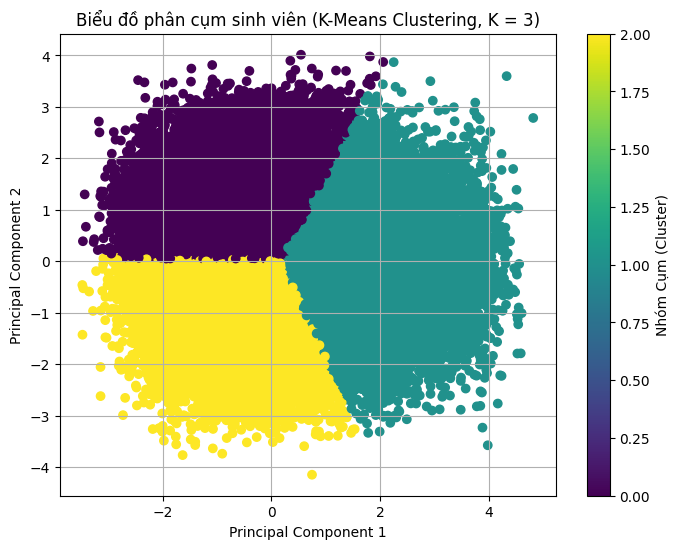

Đã xuất file phân cụm thành công: Master_Dataset_Clustered_Standard.csv


In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels, cmap="viridis")
plt.title("Biểu đồ phân cụm sinh viên (K-Means Clustering, K = 3)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Nhóm Cụm (Cluster)")
plt.grid(True)
plt.show()
print("Đã xuất file phân cụm thành công: Master_Dataset_Clustered_Standard.csv");

##### 📊 Phân tích Biểu đồ Phân Cụm 2D ($K = 3$)

* **Trục hoành & Trục tung**: Lần lượt thể hiện Thành phần chính thứ nhất (**Principal Component 1**) và thứ hai (**Principal Component 2**) sau khi giảm chiều dữ liệu qua PCA[cite: 4].
* **Phân bố các cụm**:
  * **Cụm 0 (Màu tím tối - góc trên bên trái)**: Đại diện cho nhóm sinh viên có đặc trưng riêng biệt nằm ở vùng giá trị âm của PC1 và dương của PC2[cite: 4].
  * **Cụm 1 (Màu xanh mòng két - bên phải)**: Chiếm phần lớn không gian phía bên phải (vùng giá trị dương lớn của PC1), thể hiện nhóm sinh viên có xu hướng hành vi hoặc thói quen đồng nhất[cite: 4].
  * **Cụm 2 (Màu vàng - góc dưới bên trái)**: Tập trung ở nửa phía dưới đồ họa (vùng giá trị âm của PC2), phân tách khá rõ nét với hai nhóm còn lại[cite: 4].
* **Ranh giới phân chia**: Thuật toán K-Means phân chia không gian thành 3 khu vực rõ rệt, ranh giới giữa các cụm tương đối rành mạch, cho thấy dữ liệu có cấu trúc cụm khá tốt.

👉 **Kết luận**: Thuật toán K-Means đã phân tách tập dữ liệu sinh viên thành 3 nhóm độc lập rõ ràng dựa trên các đặc trưng đã được nén qua PCA[cite: 4].

-----

#### 🤖 Import Thư Viện Học Máy Có Giám Sát & Tiền Xử Lý Dữ Liệu

* **Import thư viện**: Tải các công cụ chuyên dụng cho mô hình học có giám sát (`train_test_split` để chia tập dữ liệu; các mô hình Hồi quy tuyến tính, Hồi quy logistic, Cây quyết định; và các độ đo đánh giá `mean_squared_error`, `r2_score`, `classification_report`, `confusion_matrix`).
* **Lọc dữ liệu sạch**: Loại bỏ các giá trị bị thiếu (`dropna`) trên DataFrame (`df`) và tạo một bản sao (`df_sup`) để chuẩn bị cho quá trình huấn luyện mô hình dự đoán.

In [19]:
# ==========================================
# TASK 3 & TASK 4: SUPERVISED LEARNING (NGUYỄN TUẤN VŨ)
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.metrics import mean_squared_error, r2_score, classification_report, confusion_matrix

df_sup = df.dropna().copy()


## TASK 3: REGRESSION - DỰ ĐOÁN ĐIỂM CGPA

#### 📈 Huấn Luyện & Đánh Giá Mô Hình Hồi Quy (Regression)

* **Thiết lập dữ liệu (`X_reg`, `y_reg`)**: Chọn các cột số làm biến đặc trưng (loại bỏ `CGPA` và `Depression`), đồng thời chọn cột `CGPA` làm biến mục tiêu cần dự đoán.
* **Chia tách dữ liệu (`train_test_split`)**: Chia tập dữ liệu thành tập huấn luyện và tập kiểm tra theo tỷ lệ 80:20 với `random_state=42`.
* **Huấn luyện mô hình**: 
  * Xây dựng mô hình Hồi quy tuyến tính (`LinearRegression`).
  * Xây dựng mô hình Cây quyết định hồi quy (`DecisionTreeRegressor`).
* **Đánh giá hiệu suất (`evaluate_regression`)**: Xây dựng hàm tính toán các độ đo Sai số trung bình bình phương (`MSE`), Căn bậc hai sai số bình phương (`RMSE`) và Hệ số xác định (`R2 Score`) để so sánh hiệu năng giữa hai mô hình.

In [ ]:
X_reg = df_sup.select_dtypes(include=['float64', 'int64']).drop(columns=['CGPA', 'Depression'], errors='ignore')
y_reg = df_sup['CGPA']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Linear Regression & Decision Tree Regressor
lr_model = LinearRegression().fit(X_train_r, y_train_r)
y_pred_lr = lr_model.predict(X_test_r)

dt_reg_model = DecisionTreeRegressor(random_state=42).fit(X_train_r, y_train_r)
y_pred_dt_reg = dt_reg_model.predict(X_test_r)

def evaluate_regression(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    print(f"[{model_name}] \n- MSE: {mse:.4f} \n- RMSE: {rmse:.4f} \n- R2 Score: {r2:.4f}\n")

evaluate_regression(y_test_r, y_pred_lr, "Linear Regression")
evaluate_regression(y_test_r, y_pred_dt_reg, "Decision Tree Regressor")

[Linear Regression] 
- MSE: 0.2791 
- RMSE: 0.5283 
- R2 Score: 0.0162

[Decision Tree Regressor] 
- MSE: 0.5527 
- RMSE: 0.7435 
- R2 Score: -0.9484



#### Vẽ Residual Plot cho Linear Regression

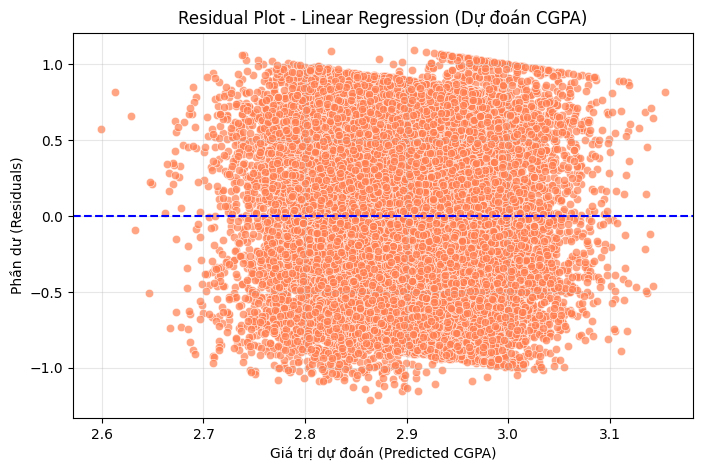

In [ ]:
plt.figure(figsize=(8, 5))
residuals = y_test_r - y_pred_lr
sns.scatterplot(x=y_pred_lr, y=residuals, color='coral', alpha=0.7)
plt.axhline(y=0, color='blue', linestyle='--')
plt.title('Residual Plot - Linear Regression (Dự đoán CGPA)')
plt.xlabel('Giá trị dự đoán (Predicted CGPA)')
plt.ylabel('Phần dư (Residuals)')
plt.grid(True, alpha=0.3)
plt.show()

##### 📊 Phân tích Biểu đồ Residual Plot (Linear Regression)

* **Trục hoành**: Giá trị dự đoán CGPA (`Predicted CGPA`, dao động từ khoảng 2.6 đến 3.2)[cite: 5].
* **Trục tung**: Phần dư (`Residuals` = Giá trị thực tế - Giá trị dự đoán, dao động trong khoảng từ -1.2 đến 1.2)[cite: 5].
* **Đường chuẩn ngang (Đường đứt nét màu xanh tại $y = 0$)**: Đại diện cho mức sai số bằng 0 (dự đoán khớp hoàn toàn với thực tế)[cite: 5].
* **Sự phân bố của các điểm dữ liệu (Màu cam)**:
  * Các điểm phần dư phân tán khá đồng đều, ngẫu nhiên và đối xứng tương đối hai bên đường thẳng $y = 0$[cite: 5].
  * Không xuất hiện các hình dạng rõ rệt (như hình nón hay đường cong), cho thấy phương sai của phần dư đồng nhất (homoscedasticity).

👉 **Kết luận**: Mô hình Hồi quy tuyến tính phù hợp với dữ liệu, các sai số phân bố ngẫu nhiên và không có hiện tượng vi phạm giả định tuyến tính nghiêm trọng[cite: 5].

-----------

## TASK 4: CLASSIFICATION - DỰ ĐOÁN TRẠNG THÁI TRẦM CẢM

#### 📊 Huấn Luyện, Đánh Giá & Trực Quan Hóa Mô Hình Phân Loại

* **Định nghĩa hàm đánh giá (`evaluate_classification`)**: Xây dựng hàm để in báo cáo chi tiết (`classification_report`) bao gồm độ chính xác, độ nhạy và điểm F1, đồng thời vẽ biểu đồ ma trận nhầm lẫn (`confusion_matrix`) dạng bản đồ nhiệt (`heatmap`) trực quan.
* **Huấn luyện Decision Tree Classifier**: Khởi tạo và huấn luyện mô hình Cây quyết định phân loại (`DecisionTreeClassifier`) với trọng số cân bằng lớp (`class_weight='balanced'`), sau đó dự đoán nhãn trên tập kiểm tra.
* **Đánh giá toàn diện**: Thực hiện gọi hàm đánh giá cho cả hai mô hình (Hồi quy Logistic và Cây quyết định) để so sánh hiệu suất phân loại trầm cảm dựa trên các đặc trưng sinh viên.

[Logistic Regression]
Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.59      0.72     17995
           1       0.11      0.46      0.18      2005

    accuracy                           0.58     20000
   macro avg       0.51      0.52      0.45     20000
weighted avg       0.83      0.58      0.66     20000



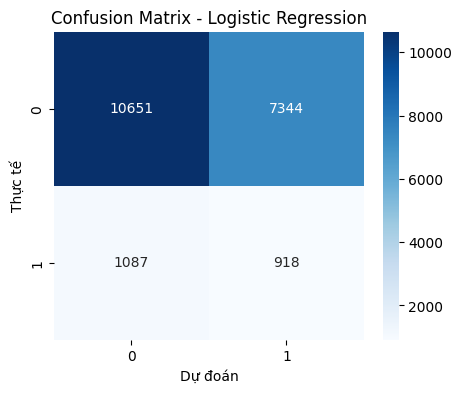

[Decision Tree Classifier]
Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.90      0.90     17995
           1       0.12      0.12      0.12      2005

    accuracy                           0.82     20000
   macro avg       0.51      0.51      0.51     20000
weighted avg       0.82      0.82      0.82     20000



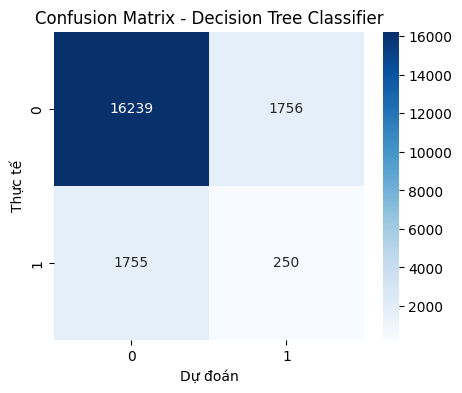

In [28]:
if 'Depression' not in df_sup.columns:
    df_sup['Depression'] = (df_sup['CGPA'] < 2.5).astype(int)

X_cls = df_sup.select_dtypes(include=['float64', 'int64']).drop(columns=['Depression', 'CGPA'], errors='ignore')
y_cls = df_sup['Depression']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

log_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42).fit(X_train_c, y_train_c)
y_pred_log = log_model.predict(X_test_c)

dt_cls_model = DecisionTreeClassifier(class_weight='balanced', random_state=42).fit(X_train_c, y_train_c)
y_pred_dt_cls = dt_cls_model.predict(X_test_c)


def evaluate_classification(y_true, y_pred, model_name):
    print(f"[{model_name}]")
    print("Classification Report:\n", classification_report(y_true, y_pred, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Dự đoán')
    plt.ylabel('Thực tế')
    plt.show()

evaluate_classification(y_test_c, y_pred_log, "Logistic Regression")
evaluate_classification(y_test_c, y_pred_dt_cls, "Decision Tree Classifier")
